# 03 — Linear SVM (LinearSVC)

**Algorithm:** LinearSVC (linear kernel, hinge loss)  
**Features:** TF-IDF (50K unigrams + bigrams)  
Linear SVM finds the maximum-margin hyperplane. With TF-IDF text features it is typically one of the strongest classical baselines.

In [1]:
import os, sys, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
warnings.filterwarnings('ignore')
sys.path.insert(0, os.path.abspath(os.path.join(os.getcwd(), '..')))
from utils import (setup_paths, evaluate_and_print, plot_confusion_matrix,
                   plot_roc_curve, plot_pr_curve, plot_learning_curve)
from sklearn.metrics import accuracy_score
BASE_DIR, FIGURES_DIR = setup_paths()

In [2]:
from preprocess import load_all_datasets, get_train_test_split
df = load_all_datasets()
X_train, X_test, y_train, y_test = get_train_test_split(df)
print(f'Train: {len(X_train):,}  |  Test: {len(X_test):,}')


  LOADING ALL DATASETS
  [1/5] Loading ISOT Dataset...
      Loaded 44,898 records  (Fake=23,481  Real=21,417)
  [2/5] Loading FakeNewsNet Dataset...
      Loaded 23,196 records  (Fake=5,755  Real=17,441)
  [3/5] Loading LIAR Dataset...
      Loaded 12,791 records  (Fake=5,657  Real=7,134)
  [4/5] Loading MultiFC Dataset...
      Loaded 31,921 records  (Fake=13,980  Real=17,941)
  [5/5] Loading BuzzFeed Dataset...
      Loaded 2,282 records  (Fake=613  Real=1,669)

  Combined total   : 115,088 records
  Fake (0)         : 49,486
  Real (1)         : 65,602

  Cleaning text...
  After clean+dedup: 104,521 records

  Source distribution:
source
ISOT           38826
MultiFC        31919
FakeNewsNet    21046
LIAR           12726
BuzzFeed           4
Train: 83,616  |  Test: 20,905


In [3]:
from sklearn.feature_extraction.text import TfidfVectorizer
tfidf = TfidfVectorizer(max_features=50000, ngram_range=(1,2),
                        sublinear_tf=True, min_df=2, max_df=0.95)
X_tr = tfidf.fit_transform(X_train)
X_te = tfidf.transform(X_test)
print(f'TF-IDF shape: {X_tr.shape}')

TF-IDF shape: (83616, 50000)


## Model Training

In [4]:
from sklearn.svm import LinearSVC
MODEL_NAME = 'Linear SVM'
model = LinearSVC(C=1.0, max_iter=2000, random_state=42)
t0 = time.time()
model.fit(X_tr, y_train)
train_time = time.time() - t0
print(f'Training completed in {train_time:.2f}s')
print(f'Iterations: {model.n_iter_}')

Training completed in 6.36s
Iterations: 11


In [5]:
metrics, y_pred, y_prob = evaluate_and_print(model, X_te, y_test, MODEL_NAME, train_time)


  Linear SVM — Evaluation Results
  Accuracy          : 0.8242
  Precision         : 0.8234
  Recall            : 0.8242
  F1 Score          : 0.8232
  AUC-ROC           : 0.9108
  Train Time (s)    : 6.36s

              precision    recall  f1-score   support

    Fake (0)       0.80      0.75      0.78      8532
    Real (1)       0.84      0.87      0.85     12373

    accuracy                           0.82     20905
   macro avg       0.82      0.81      0.82     20905
weighted avg       0.82      0.82      0.82     20905



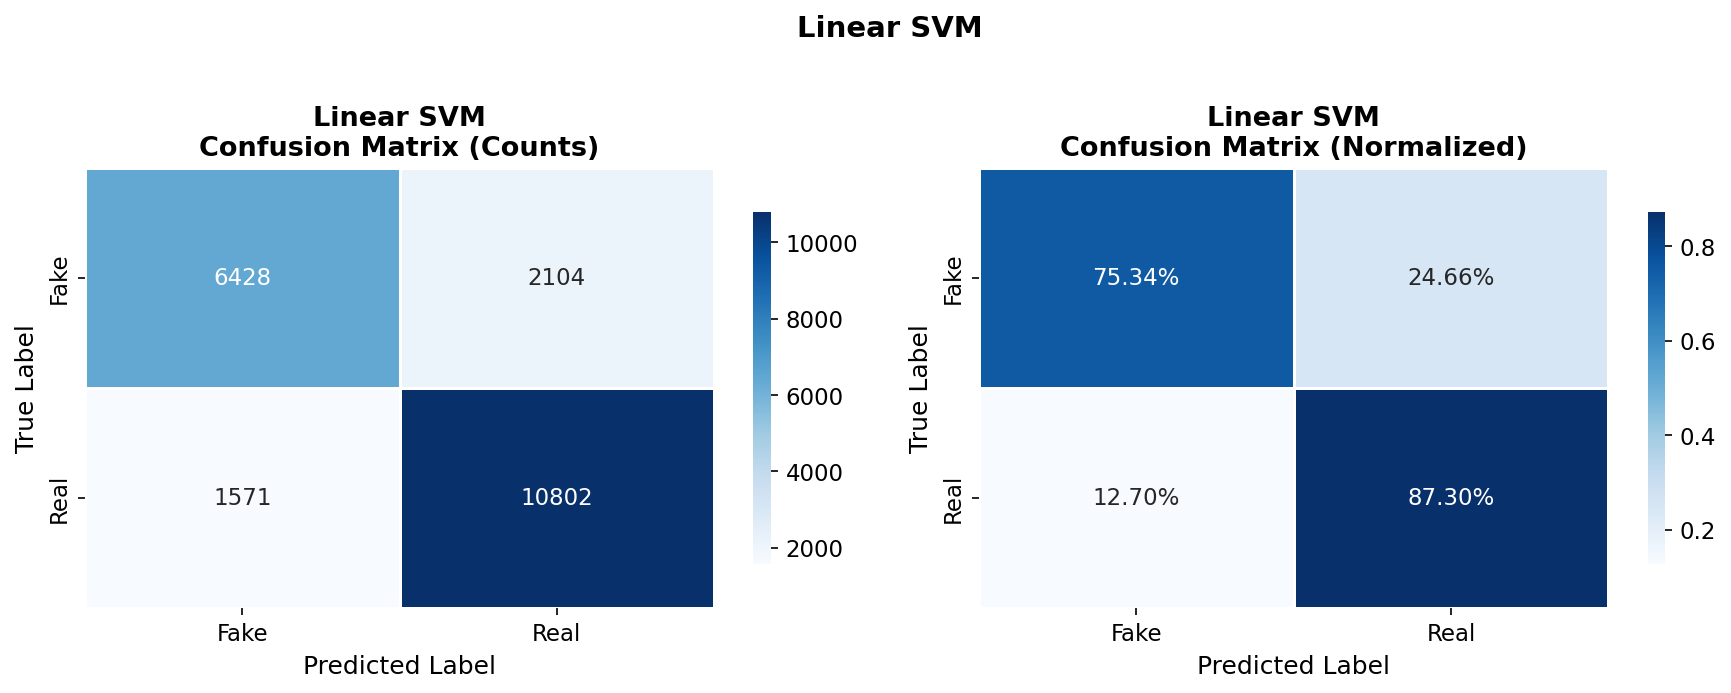

In [6]:
plot_confusion_matrix(y_test, y_pred, MODEL_NAME, FIGURES_DIR)

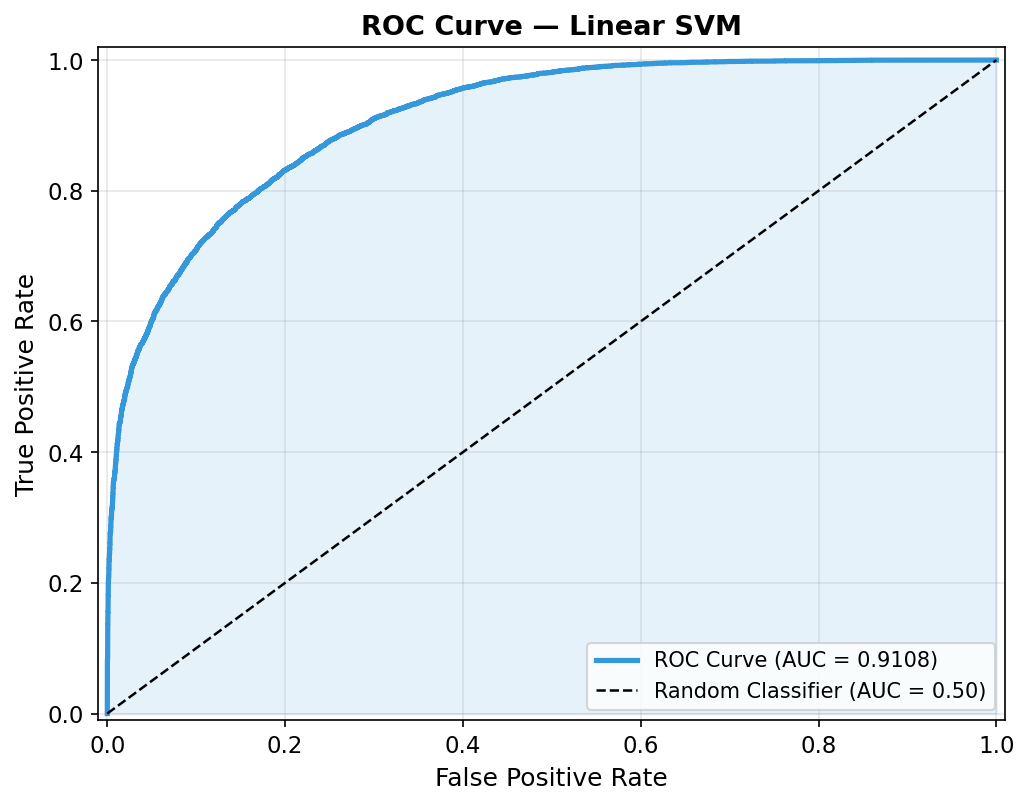

In [7]:
plot_roc_curve(y_test, y_prob, MODEL_NAME, FIGURES_DIR)

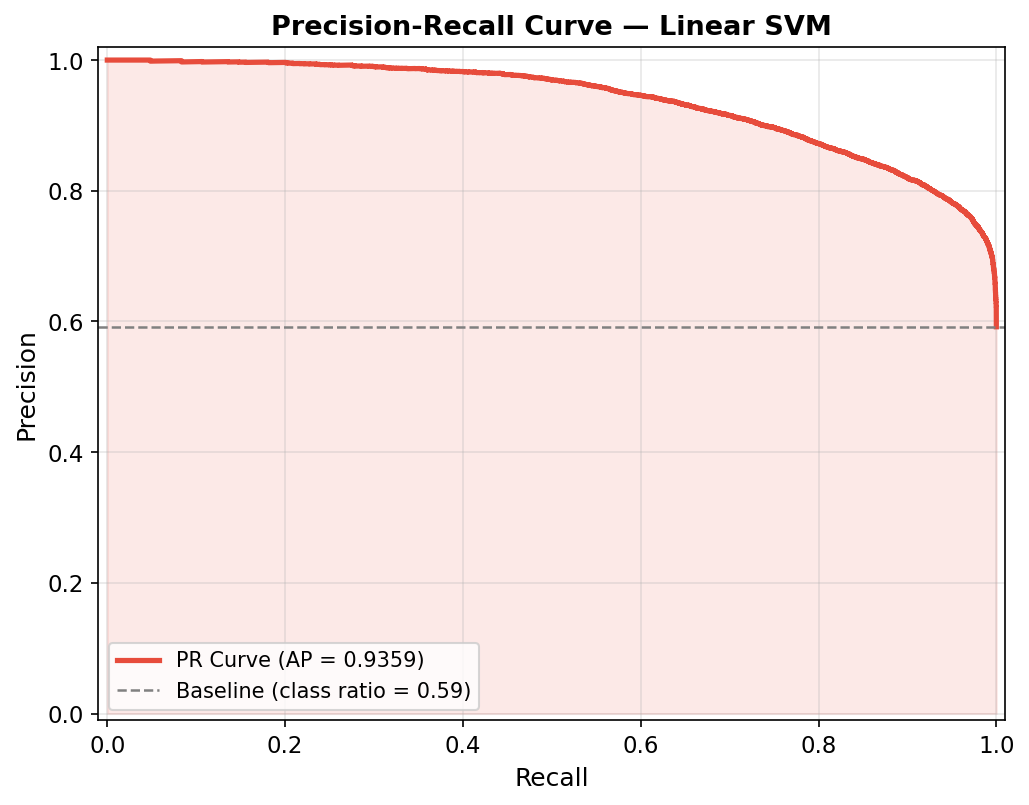

In [8]:
plot_pr_curve(y_test, y_prob, MODEL_NAME, FIGURES_DIR)

## Learning Curve

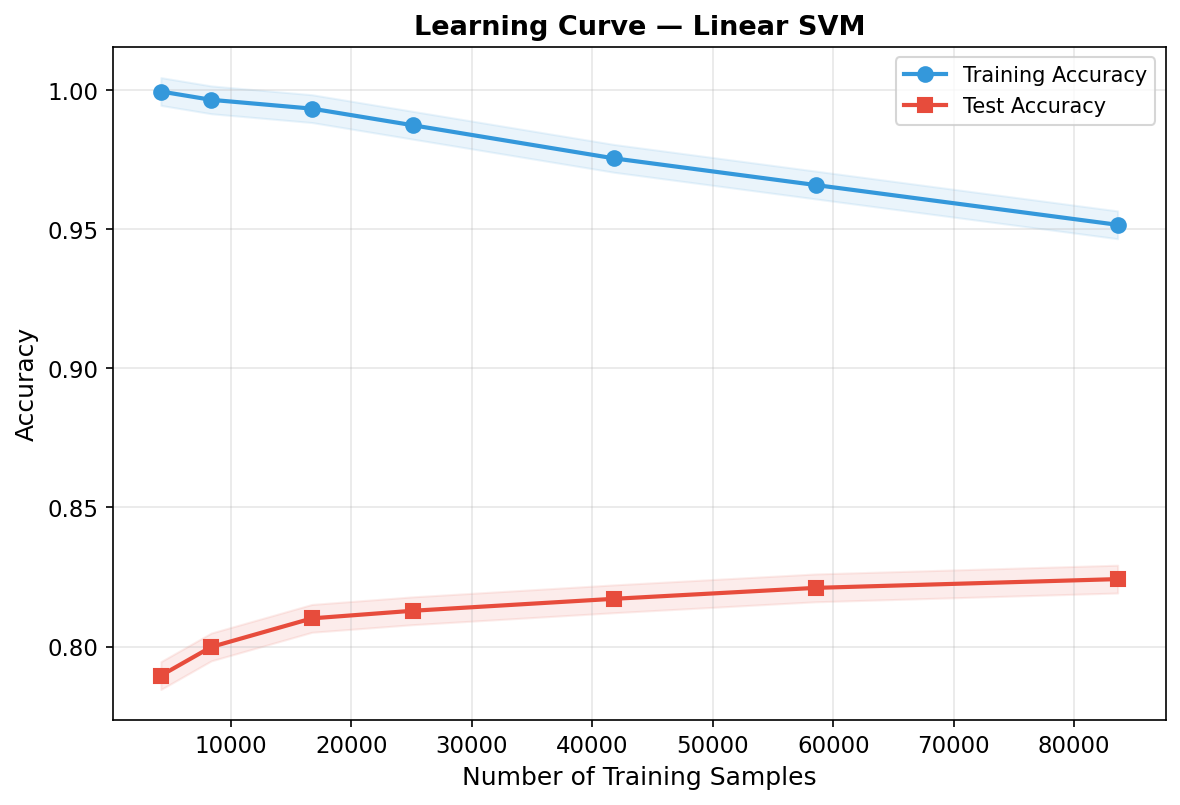

([4180, 8361, 16723, 25084, 41808, 58531, 83616],
 [0.9995215311004785,
  0.996531515368975,
  0.993362434969802,
  0.9874023281773242,
  0.9754831611174895,
  0.9659154977704123,
  0.9516001722158438],
 [0.7895718727577135,
  0.7998564936618034,
  0.8101411145658933,
  0.8128677349916288,
  0.8171729251375269,
  0.8210954317149007,
  0.824252571155226])

In [9]:
plot_learning_curve(model, X_tr, y_train, X_te, y_test, MODEL_NAME, FIGURES_DIR)

## Regularisation Strength (C) vs Accuracy

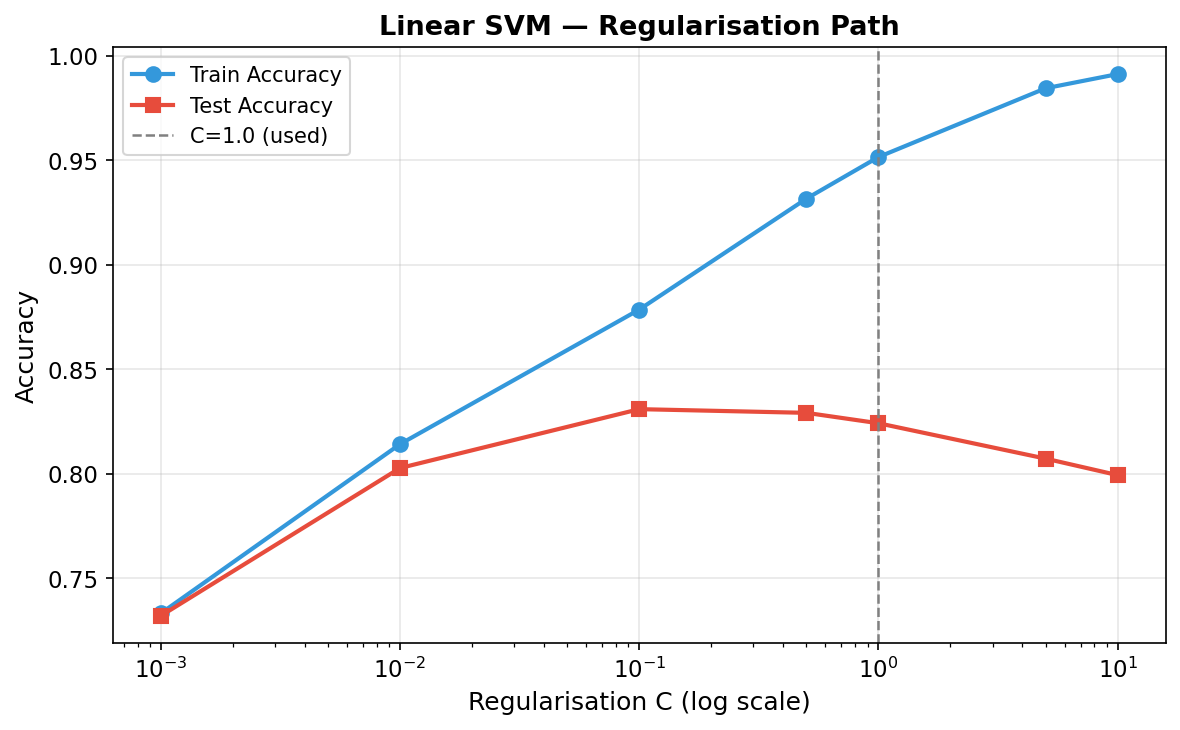

In [10]:
C_vals = [0.001, 0.01, 0.1, 0.5, 1.0, 5.0, 10.0]
tr_accs, te_accs = [], []
for C in C_vals:
    m = LinearSVC(C=C, max_iter=1000, random_state=42)
    m.fit(X_tr, y_train)
    tr_accs.append(accuracy_score(y_train, m.predict(X_tr)))
    te_accs.append(accuracy_score(y_test, m.predict(X_te)))

fig, ax = plt.subplots(figsize=(8, 5))
ax.semilogx(C_vals, tr_accs, 'o-', color='#3498db', lw=2, ms=7, label='Train Accuracy')
ax.semilogx(C_vals, te_accs, 's-', color='#e74c3c', lw=2, ms=7, label='Test Accuracy')
ax.axvline(1.0, color='grey', linestyle='--', lw=1.2, label='C=1.0 (used)')
ax.set_xlabel('Regularisation C (log scale)')
ax.set_ylabel('Accuracy')
ax.set_title('Linear SVM — Regularisation Path')
ax.legend(fontsize=10); ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, 'linear_svm_reg_path.png'), dpi=150, bbox_inches='tight')
plt.show()

## Top Discriminative Features

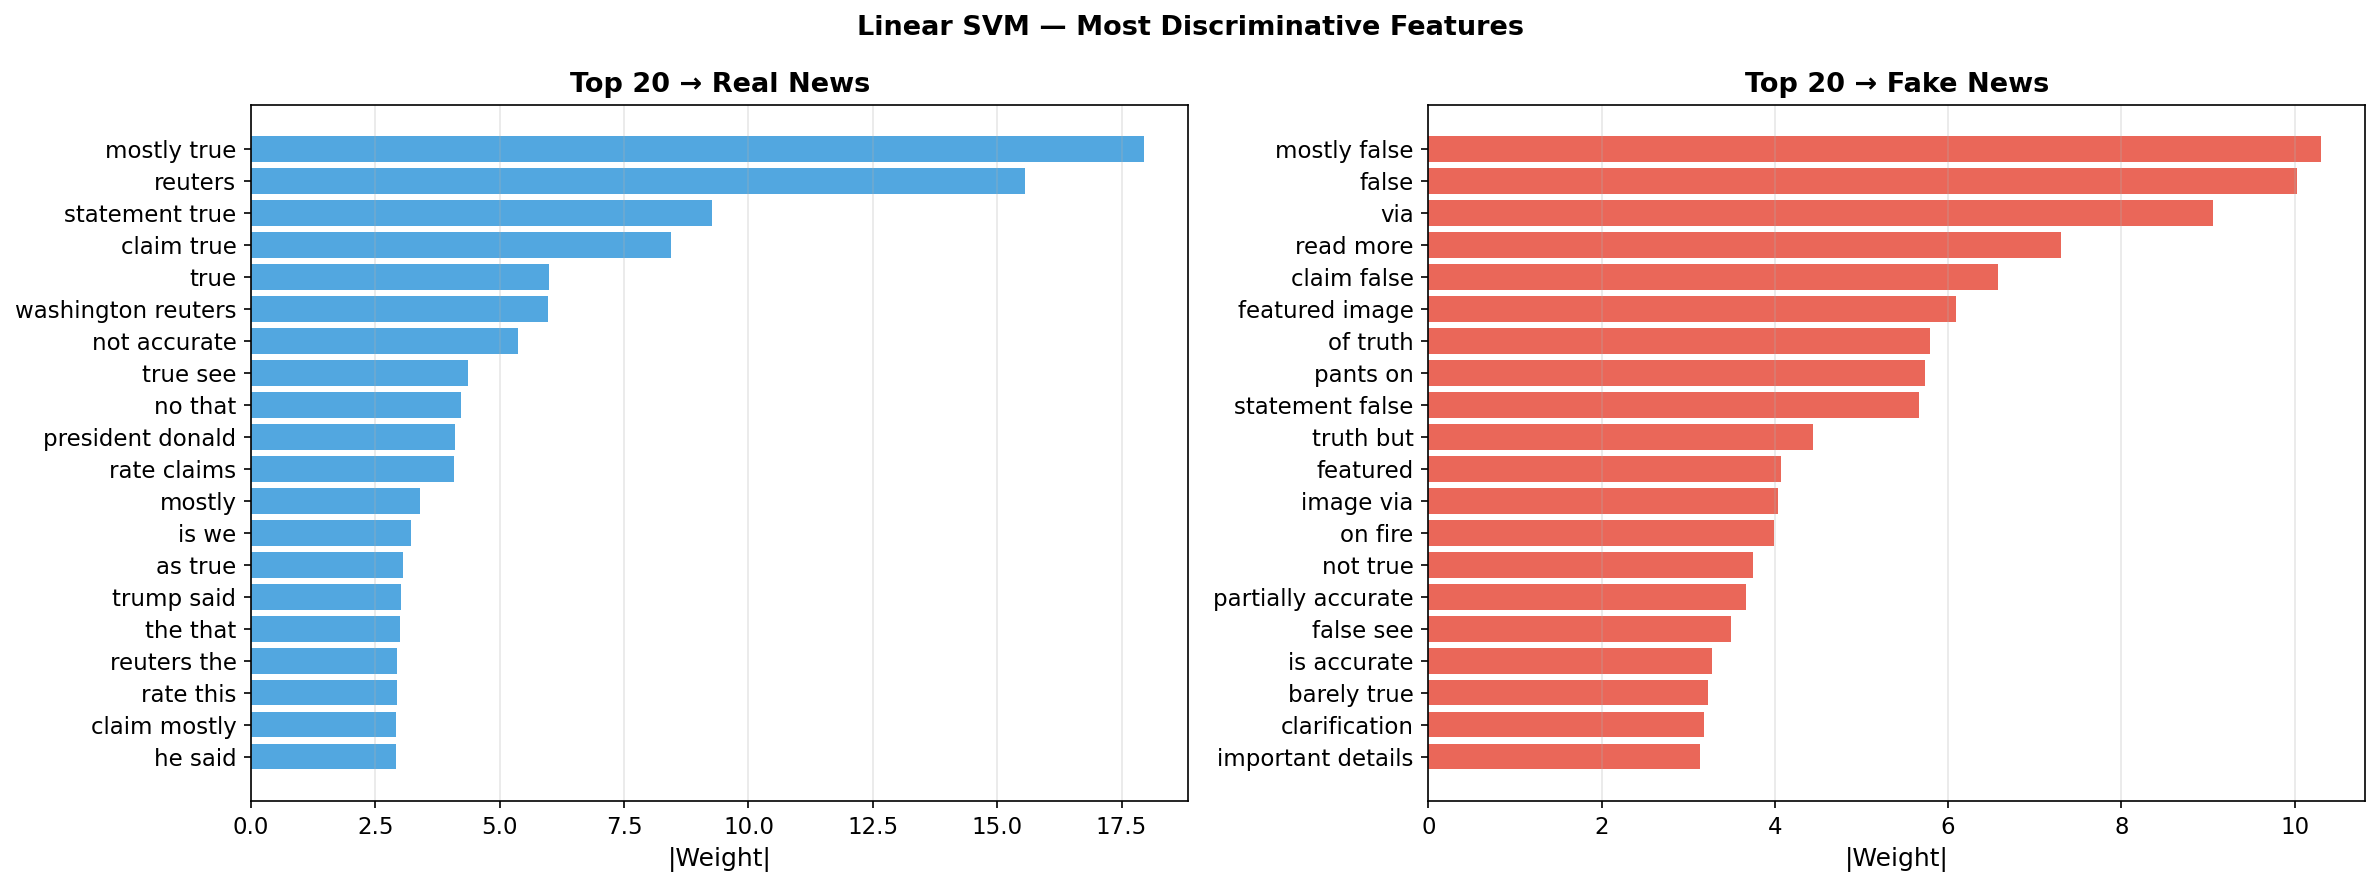

In [11]:
feat_names = np.array(tfidf.get_feature_names_out())
coefs = model.coef_[0]
top_n = 20
top_real = np.argsort(coefs)[-top_n:][::-1]
top_fake = np.argsort(coefs)[:top_n]

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for ax, idx, color, title in zip(
    axes,
    [top_real, top_fake],
    ['#3498db', '#e74c3c'],
    ['Top 20 → Real News', 'Top 20 → Fake News']
):
    ax.barh(feat_names[idx][::-1], np.abs(coefs[idx])[::-1], color=color, alpha=0.85)
    ax.set_xlabel('|Weight|'); ax.set_title(title); ax.grid(axis='x', alpha=0.3)
plt.suptitle('Linear SVM — Most Discriminative Features', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, 'linear_svm_top_features.png'), dpi=150, bbox_inches='tight')
plt.show()